# Prelab 05 Optional Supplement: Plotting with matplotlib

*This optional supplement to Prelab 05 shows how to make the same plots as `plot_data()` with matplotlib, step by step: data with error bars, labels with LaTeX, a model line, and a residuals panel.*

## Introduction

In Phys 119, `plot_data()` makes useful plots with just a single command. This supplement shows what happens behind that command: how the same figures are built with `matplotlib`, the Python plotting library that `plot_data()` itself uses. This notebook is for the curious folks wanting to better understand how to duplicate many of the features of `plot_data()` when the custom Phys 119 functions are not available.

We will rebuild, one feature at a time, the plots you made in Prelab 05:

1. a scatter plot of data with error bars;
2. axis labels, a title and a legend, including mathematical symbols written in LaTeX;
3. a straight-line model drawn over the data;
4. a residuals plot underneath.

After each step we compare with `plot_data()`, so you can see that the two give the same figure.

## Part 1: Getting set up

Plotting is not a built-in part of Python. Instead, we import a library that provides it: `matplotlib`, and in particular its `pyplot` module, which by convention is given the short name `plt`. We also import `numpy` and our custom phys119 functions, so we can compare with `plot_data()` along the way. Run the cell below.

In [1]:
# Run me to import the relevant libraries

%reset -f

import numpy as np
import matplotlib.pyplot as plt
from phys119_functions import *

We will use the spring data from Prelab 05: the force $F$ (stored in `FVec`) needed to compress a spring by a range of displacements $\Delta x$ (`DxVec`), with the uncertainties in the force $\delta F$ (`dFVec`) and in the displacements $\delta(\Delta x)$ (`dDxVec`).

In [2]:
# Run me to generate spring data
# (compressions Dx in m, forces F in N, with their uncertainties)

DxVec  = np.array([0.00, 0.12, 0.21, 0.29, 0.40, 0.48, 0.60])  # units = m
dDxVec = np.array([0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01])  # units = m
FVec   = np.array([0.00, 0.26, 0.43, 0.63, 0.81, 1.05, 1.23])  # units = N
dFVec  = np.array([0.02, 0.02, 0.03, 0.03, 0.03, 0.04, 0.04])  # units = N

## Part 2: Our first matplotlib plot

Run the cell below to create a simple scatter plot of $F$ versus $\Delta x$, including the uncertainties $\delta F$ as error bars. The code is explained in the next cell.

In [ ]:
# Run me to create a plot of F versus Dx with matplotlib

# Define variables from the experimental data.
x_data = DxVec
y_data = FVec
dy_data = dFVec

# Create a new figure.
plt.figure()

# Plot y_data versus x_data as markers with attached error bars dy_data.
plt.errorbar(x=x_data, y=y_data, yerr=dy_data, fmt='bo')

# Display the figure.
plt.show()

Let's have a look at the different Python commands used to create this plot:
- `plt`: specifies that we want to use the `matplotlib` plotting library (its `pyplot` module);
- `plt.figure()`: creates a new, empty figure that we can draw a plot in;
- `plt.errorbar()`: draws $y$ versus $x$ as markers with attached error bars;
- `plt.show()`: displays the figure.

We used the following built-in **parameters** of the function `plt.errorbar()`:
- `x`: the data for the $x$ axis;
- `y`: the data for the $y$ axis;
- `yerr`: the error bar sizes for the $y$-axis data;
- `fmt`: the format for the data points.

In our case, we passed the following **arguments** to `plt.errorbar()` when we called it:
- `x_data` for the parameter `x`, i.e. the vector of $\Delta x$ values;
- `y_data` for the parameter `y`, i.e. the vector of $F$ values;
- `dy_data` for the parameter `yerr`, i.e. the vector of $\delta F$ values for the error bars;
- `'bo'` for the parameter `fmt`, to specify blue (`b`) circles (`o`) for the data points.

*Note that `xerr` (the error bar sizes for the $x$-axis data) also exists as a parameter. However, we will often find that the uncertainties in the $y$ values are more significant than those in the $x$ values, so the uncertainty in $x$ can often be neglected.*

**Compare with `plot_data()`:** the single command `plot_data(x=DxVec, y=FVec, dy=dFVec)` from Prelab 05 does all of this for you, along with a few of the extra details we will add next.

#### **Your turn #1:**

In the cell below, replace the blue circles with red crosses by changing the format to `fmt='rx'`, and run the cell. Then try a few other combinations: other colours include `g` (green) and `k` (black), and other markers include `s` (squares) and `^` (triangles).

In [ ]:
# Change the format of the data points and run this cell

plt.figure()
plt.errorbar(x=x_data, y=y_data, yerr=dy_data, fmt='bo')
plt.show()

#### Answer:

In [ ]:
plt.figure()
plt.errorbar(x=x_data, y=y_data, yerr=dy_data, fmt='rx')
plt.show()

## Part 3: Adding further details to our plot

Next, let's add further important information to our plot: axis labels, a title and a legend. We will also make the markers smaller and add light grid lines, which is what `plot_data()` does.

In [ ]:
# Run me to add a title, axis labels, a legend and grid lines to the graph

plt.figure()

# The label is used for the legend
plt.errorbar(x=x_data, y=y_data, yerr=dy_data, fmt='bo', markersize=3, label="Round 1 data")

plt.title("Hooke's law investigation using spring compression")
plt.xlabel("Displacement of spring from equilibrium (m)")
plt.ylabel("Force (N)")
plt.legend()        # show the legend
plt.grid(alpha=0.3) # add grid lines

plt.show()

We now have a complete plot! Notice that the title describes the purpose of the plot, and the axis labels describe the quantities (with the units). Other things to note:

* The `markersize` parameter of `plt.errorbar()` sets how large the markers are. In the first version of the plot, the error bars of the first data point were hidden behind the marker, so here we shrink the markers to make the small error bars visible.

* The `label` parameter of `plt.errorbar()` sets the text for the data in the legend, and `plt.legend()` draws the legend.

* `plt.grid(alpha=0.3)` adds grid lines; `alpha` sets how transparent they are, from 0 (invisible) to 1 (solid).

* matplotlib chooses the axis tick marks (the numbers along each axis) and the axis limits automatically, and its choices are usually reasonable. If they are not, `plt.xlim([min, max])` and `plt.xticks([0.1, 0.2, 0.3])` (and their `y` versions) let you set them yourself.

**Compare with `plot_data()`:** this is the same figure that `plot_data()` makes when you give it `title`, `x_label`, `y_label` and `data_label`. Run the cell below to check.

In [ ]:
# Run me to make the same plot with plot_data()

plot_data(
    x=DxVec, y=FVec, dy=dFVec,
    title="Hooke's law investigation using spring compression",
    x_label="Displacement of spring from equilibrium (m)",
    y_label="Force (N)",
    data_label="Round 1 data",
)

#### **Your turn #2:**

Test your understanding by playing around with the code in the cell below. Change the text inside `plt.title("...")`, `plt.xlabel("...")` and `plt.ylabel("...")`, and plot your data with different size markers.

In [ ]:
# Modify the labels and the marker size, and run this cell

plt.figure()
plt.errorbar(x=x_data, y=y_data, yerr=dy_data, fmt='bo', markersize=3, label="Round 1 data")
plt.title("Hooke's law investigation using spring compression")
plt.xlabel("Displacement of spring from equilibrium (m)")
plt.ylabel("Force (N)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#### Answer:

There is no single correct answer. For example, the cell below uses larger markers and different labels.

In [ ]:
plt.figure()
plt.errorbar(x=x_data, y=y_data, yerr=dy_data, fmt='bo', markersize=6, label="Spring data")
plt.title("Force needed to compress a spring")
plt.xlabel("Compression (m)")
plt.ylabel("Force applied (N)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Part 4: Using LaTeX in titles and labels

Titles, axis labels and legend entries can include mathematical symbols written in LaTeX, like the $F$ and $\Delta x$ in the text of this notebook. Put the LaTeX between a pair of dollar signs, `$...$`, and matplotlib draws it as maths. The one complication is the backslash that starts every LaTeX command, such as `\Delta`, because Python also gives backslashes a special meaning inside text. There are two ways to deal with that.

**1. A raw string, with `r` before the opening quotation mark.** In a raw string, Python leaves every backslash alone, so you write LaTeX exactly as you would anywhere else:

```python
plt.xlabel(r"Displacement $\Delta x$ (m)")
```

**2. An ordinary string, with every backslash doubled.** In an ordinary string, Python reads `\\` as a single backslash:

```python
plt.xlabel("Displacement $\\Delta x$ (m)")
```

Both give exactly the same label. Run the cell below to see one of each.

In [ ]:
# Run me to see LaTeX in the axis labels: a raw string and an ordinary string

plt.figure()
plt.errorbar(x=DxVec, y=FVec, yerr=dFVec, fmt='bo', markersize=3, label="Round 1 data")
plt.title("Hooke's law investigation using spring compression, $\\Delta x$") # double slash
plt.xlabel(r"Displacement of spring from equilibrium, $\Delta x$ (m)")       # raw string
plt.ylabel("Force, F (N)")                                            
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#### Starting a new line

`\n` starts a new line in a title or label, which is useful when the text is long. Here the two kinds of string behave differently:

* In an **ordinary string**, `\n` is a new line: `"Displacement of spring,\n$\\Delta x$ (m)"`.
* In a **raw string**, `\n` is just a backslash and the letter n, because raw strings leave every backslash alone. Instead, put an ordinary `"\n"` between two raw pieces. Python joins pieces of text written side by side into one string:

```python
plt.xlabel(r"Displacement of spring," "\n" r"$\Delta x$ (m)")
```

#### Common mistakes

| You typed | What happens |
|---|---|
| `"$\theta$"` (ordinary string, single backslash) | Python reads `\t` as a tab, so matplotlib gets a tab followed by "heta" and reports an error. The same happens with other commands that start with a, b, f, n, r or v, such as `\alpha`, `\beta`, `\frac`, `\nu` and `\rho`. Use `r"$\theta$"` or `"$\\theta$"`. |
| `r"$\\Delta x$"` (raw string, double backslash) | The two pieces of advice combined: matplotlib gets two backslashes and reports an error. Use one or the other. |
| `r"Line 1\nLine 2"` (raw string) | The label shows `\n` as text instead of starting a new line. Use `r"Line 1" "\n" r"Line 2"`. |
| `"Force $F (N)"` | A `$` with no partner: matplotlib shows the text as it is, dollar sign and all. |

When matplotlib cannot read the LaTeX in a label, it stops with a long error message. `plot_data()` checks the labels first and gives a short message saying which label to fix, and how.

#### **Your turn #3:**

In the cell below:
1. Add the symbol $F$ to the y-axis label, using a raw string.
2. Give the title a second line, reading "$F$ versus $\Delta x$", using raw pieces with an ordinary `"\n"` between them.

In [ ]:
# Add LaTeX and a second line, and run this cell

plt.figure()
plt.errorbar(x=DxVec, y=FVec, yerr=dFVec, fmt='bo', markersize=3, label="Round 1 data")
plt.title("Hooke's law investigation using spring compression")
plt.xlabel(r"Displacement of spring from equilibrium, $\Delta x$ (m)")
plt.ylabel("Force (N)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#### Answer:

In [ ]:
plt.figure()
plt.errorbar(x=DxVec, y=FVec, yerr=dFVec, fmt='bo', markersize=3, label="Round 1 data")
plt.title(r"Hooke's law investigation using spring compression" "\n" r"$F$ versus $\Delta x$")
plt.xlabel(r"Displacement of spring from equilibrium, $\Delta x$ (m)")
plt.ylabel(r"Force, $F$ (N)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Part 5: Adding a model line

In Prelab 05, `plot_data(..., m=2, b=0)` drew the straight-line model $y = mx + b$ over the data. To draw a line with matplotlib, we need a set of points along it, which we then join up:

1. `np.linspace(start, stop, num)` makes `num` evenly spaced $x$ values from `start` to `stop`. We use 100 values from the smallest to the largest $\Delta x$, which is what `plot_data()` does.
2. For each of those $x$ values, the model gives $y = mx + b$. Because `x_model` is a numpy array, `m * x_model + b` calculates all 100 values at once.
3. `plt.plot(x, y, 'r-')` draws a red (`r`) solid line (`-`) through the points.

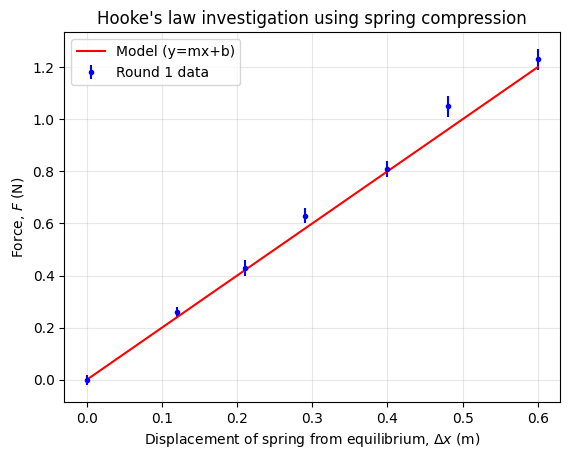

In [3]:
# Run me to draw the model line y = mx + b over the data

m = 2
b = 0

x_model = np.linspace(start=np.min(DxVec), stop=np.max(DxVec), num=100)
y_model = m * x_model + b

plt.figure()
plt.errorbar(x=DxVec, y=FVec, yerr=dFVec, fmt='bo', markersize=3, label="Round 1 data")
plt.plot(x_model, y_model, 'r-', label="Model (y=mx+b)")
plt.title("Hooke's law investigation using spring compression")
plt.xlabel(r"Displacement of spring from equilibrium, $\Delta x$ (m)")
plt.ylabel(r"Force, $F$ (N)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#### Showing the values of $m$ and $b$ in the legend

`plot_data()` also lists the values of $m$ and $b$ in the legend. To put a number inside a piece of text, we use an **f-string**: an `f` before the opening quotation mark, and the value in curly brackets. `f"m = {m:.2f}"` gives `m = 2.00`, where `:.2f` asks for 2 decimal places.

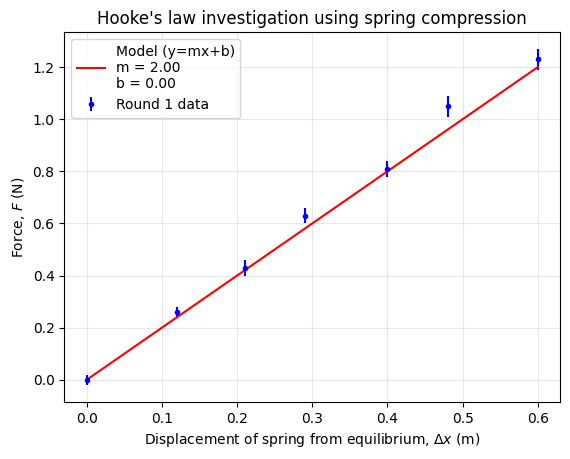

In [4]:
# Run me to see slope and y-intercept values added to the legend

plt.figure()
plt.errorbar(x=DxVec, y=FVec, yerr=dFVec, fmt='bo', markersize=3, label="Round 1 data")
plt.plot(x_model, y_model, 'r-', label=f"Model (y=mx+b)\nm = {m:.2f}\nb = {b:.2f}")
plt.title("Hooke's law investigation using spring compression")
plt.xlabel(r"Displacement of spring from equilibrium, $\Delta x$ (m)")
plt.ylabel(r"Force, $F$ (N)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Compare with `plot_data()`:** run the cell below to see `plot_data()` draw the same model line. Its legend gives $m$ and $b$ to 3 significant figures, which for these values is the same as 2 decimal places. The order of the legend is different: matplotlib always lists lines before data with error bars, while `plot_data()` arranges its legend to put the data first.

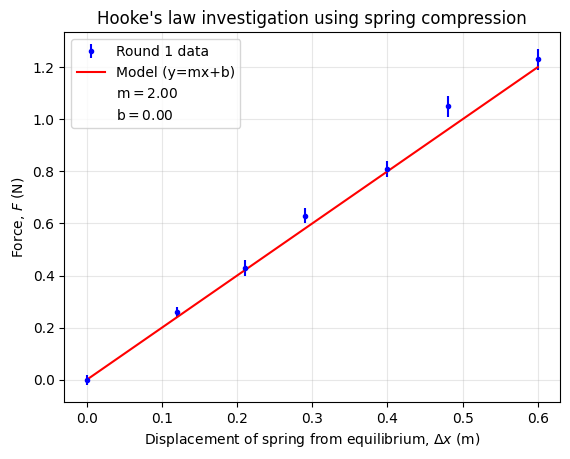

In [5]:
# Run me to make the same plot with plot_data()

plot_data(
    x=DxVec, y=FVec, dy=dFVec,
    m=2, b=0,
    title="Hooke's law investigation using spring compression",
    x_label=r"Displacement of spring from equilibrium, $\Delta x$ (m)",
    y_label=r"Force, $F$ (N)",
    data_label="Round 1 data",
)

#### **Your turn #4:**

In Prelab 05, a slope of 2.1 N/m fitted the spring data better than 2.0 N/m. In the cell below, change `m` to `2.1`, run the cell, and check that your plot matches the `plot_data()` plot underneath it, which also uses `m=2.1`. Does the line pass through more of the error bars than before?

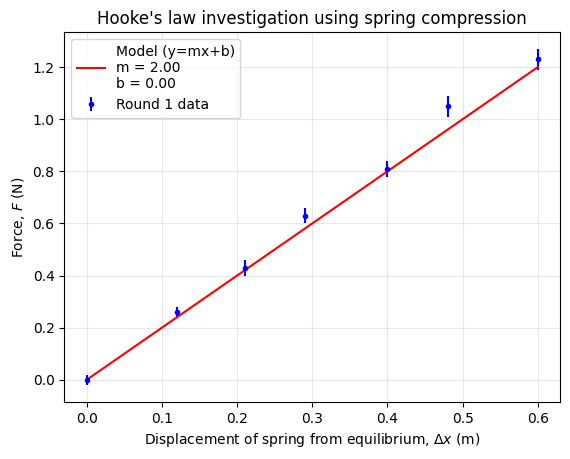

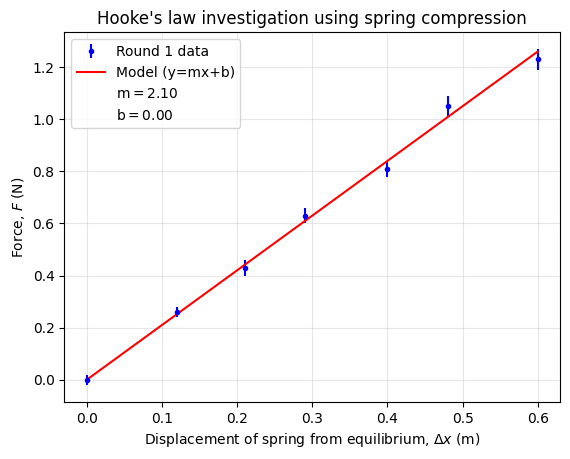

In [6]:
# Change m to 2.1 and run this cell

m = 2
b = 0

x_model = np.linspace(start=np.min(DxVec), stop=np.max(DxVec), num=100)
y_model = m * x_model + b

plt.figure()
plt.errorbar(x=DxVec, y=FVec, yerr=dFVec, fmt='bo', markersize=3, label="Round 1 data")
plt.plot(x_model, y_model, 'r-', label=f"Model (y=mx+b)\nm = {m:.2f}\nb = {b:.2f}")
plt.title("Hooke's law investigation using spring compression")
plt.xlabel(r"Displacement of spring from equilibrium, $\Delta x$ (m)")
plt.ylabel(r"Force, $F$ (N)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

plot_data(
    x=DxVec, y=FVec, dy=dFVec,
    m=2.1, b=0,
    title="Hooke's law investigation using spring compression",
    x_label=r"Displacement of spring from equilibrium, $\Delta x$ (m)",
    y_label=r"Force, $F$ (N)",
    data_label="Round 1 data",
)

#### Answer:

With `m = 2.1` the two plots match, including the legend values $m = 2.10$ and $b = 0.00$. The line now passes through or very close to all of the error bars, where with `m = 2` it ran below most of the data points, which is why 2.1 was the better fit in Prelab 05.

## Part 6: Adding a residuals plot

The last step is the residuals plot that `plot_data(..., residuals=True)` draws underneath. Recall that each residual is the measured value minus the value the model predicts:

$$r_i = y_i - (m x_i + b)$$

and that its uncertainty is the same as the uncertainty in $y_i$. With numpy arrays, `FVec - (m * DxVec + b)` calculates all the residuals at once.

So far each figure has held one plot, and commands such as `plt.xlabel()` have applied to "the current plot". A figure with two plots needs a way to say which one each command is for:

* `fig, (ax_top, ax_bottom) = plt.subplots(nrows=2, ncols=1, ...)` creates a figure with two sets of axes, one above the other, and gives us a name for each: `ax_top` and `ax_bottom`.
* We then draw on each set of axes by name, as in `ax_top.errorbar(...)`. Most commands are the same as before, but the ones that set labels change their names: `plt.xlabel()` becomes `ax.set_xlabel()`, `plt.ylabel()` becomes `ax.set_ylabel()`, and `plt.title()` becomes `ax.set_title()`.
* `sharex=True` makes the two plots share their $x$ axis, so the points line up vertically; `height_ratios=[2, 1]` makes the top plot twice as tall as the bottom one; and `figsize=(7, 6)` sets the size of the figure in inches.
* `fig.subplots_adjust(hspace=0.08)` reduces the gap between the two plots, which matplotlib otherwise leaves quite wide.

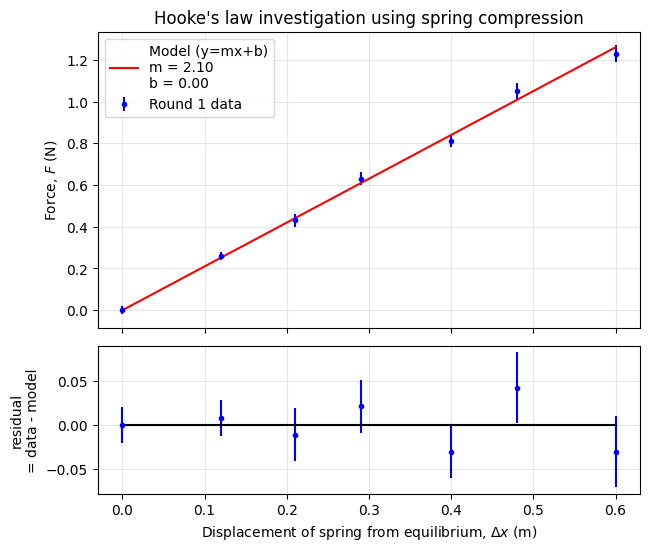

In [7]:
# Run me to draw the data and model, with the residuals underneath

m = 2.1
b = 0

x_model = np.linspace(start=np.min(DxVec), stop=np.max(DxVec), num=100)
y_model = m * x_model + b
residuals = FVec - (m * DxVec + b)

fig, (ax_top, ax_bottom) = plt.subplots(nrows=2, ncols=1, sharex=True,
                                        height_ratios=[2, 1], figsize=(7, 6))
fig.subplots_adjust(hspace=0.08)   # bring the two plots close together

# Top: the data and the model, as before
ax_top.errorbar(x=DxVec, y=FVec, yerr=dFVec, fmt='bo', markersize=3, label="Round 1 data")
ax_top.plot(x_model, y_model, 'r-', label=f"Model (y=mx+b)\nm = {m:.2f}\nb = {b:.2f}")
ax_top.set_title("Hooke's law investigation using spring compression")
ax_top.set_ylabel(r"Force, $F$ (N)")
ax_top.legend()
ax_top.grid(alpha=0.3)

# Bottom: the residuals, with the same error bars as the data
ax_bottom.errorbar(x=DxVec, y=residuals, yerr=dFVec, fmt='bo', markersize=3)
ax_bottom.hlines(y=0, xmin=np.min(DxVec), xmax=np.max(DxVec), color='k')
ax_bottom.set_xlabel(r"Displacement of spring from equilibrium, $\Delta x$ (m)")
ax_bottom.set_ylabel("residual\n= data - model")
ax_bottom.grid(alpha=0.3)

plt.show()

Some things to note:

* `ax_bottom.hlines(y=0, xmin=..., xmax=...)` draws the horizontal residual = 0 line, in black (`'k'`), across the range of the data. A data point exactly on the model line has a residual of 0.
* Only the bottom plot gets an $x$-axis label: because of `sharex=True`, it applies to both.
* The residual axis label uses `\n` in an ordinary string to put "= data - model" on a second line.

**Compare with `plot_data()`:** run the cell below to see `plot_data(..., residuals=True)` draw the same figure.

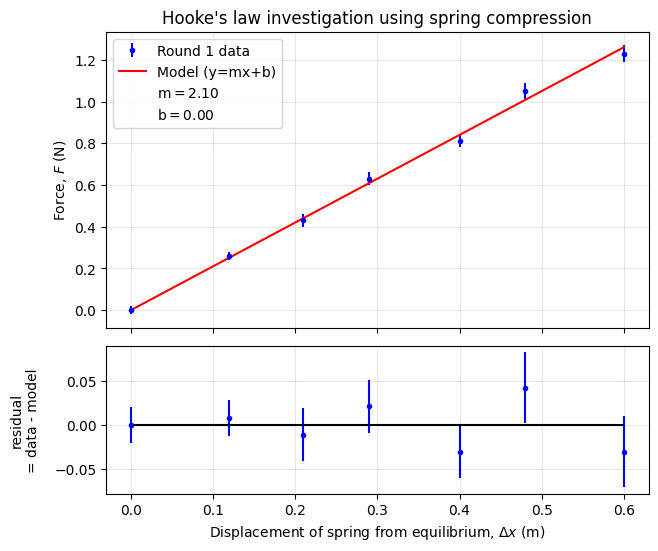

In [8]:
# Run me to make the same figure with plot_data()

plot_data(
    x=DxVec, y=FVec, dy=dFVec,
    m=2.1, b=0,
    title="Hooke's law investigation using spring compression",
    x_label=r"Displacement of spring from equilibrium, $\Delta x$ (m)",
    y_label=r"Force, $F$ (N)",
    data_label="Round 1 data",
    residuals=True,
)

You have now built every part of the figures that `plot_data()` makes. The real function adds what makes it easier to use in the labs: it checks your data and labels before drawing and gives a short message when something is wrong, it uses the names of your variables as axis labels when you leave the labels out, and it gives $m$ and $b$ to 3 significant figures.

#### **Your turn #5:**

At the end of Prelab 05, you made a final best-fit plot of the Ohm's law data with `plot_data(..., residuals=True)`. Run the first cell below to load the data, then use the second cell to make the same final best-fit plot **with matplotlib**:

* the best-fit line with $m = 9.9\ \Omega$ and $b = 0$ V, and a residuals plot underneath;
* the title "Ohm's law investigation using two resistors in series";
* the axis labels "Current in the circuit, $I$ (A)" and "Voltage drop across $R_1$, $V_{R_1}$ (V)", written in LaTeX;
* the data label "Round 1 data".

You can copy the code from Part 6 and change what needs changing.

In [ ]:
# Run me to load Ohm's law data
# (battery voltage Vs in V, voltage across R1 in V,
#  current through R1 in A, with their uncertainties)

VsVec   = np.array([0.00, 0.45, 0.90, 1.10, 1.65, 2.10, 2.70, 3.20])
Vr1Vec  = np.array([0.00, 0.11, 0.19, 0.28, 0.41, 0.53, 0.67, 0.80])
dVr1Vec = np.array([0.02, 0.03, 0.02, 0.02, 0.03, 0.02, 0.03, 0.03])
IVec    = np.array([0.000, 0.009, 0.020, 0.029, 0.043, 0.053, 0.070, 0.078])
dIVec   = np.array([0.005, 0.010, 0.005, 0.005, 0.010, 0.005, 0.010, 0.010])

In [ ]:
# Your plotting code here



#### Answer:

In [ ]:
m = 9.9
b = 0

x_model = np.linspace(start=np.min(IVec), stop=np.max(IVec), num=100)
y_model = m * x_model + b
residuals = Vr1Vec - (m * IVec + b)

fig, (ax_top, ax_bottom) = plt.subplots(nrows=2, ncols=1, sharex=True,
                                        height_ratios=[2, 1], figsize=(7, 6))
fig.subplots_adjust(hspace=0.08)   # bring the two plots close together

ax_top.errorbar(x=IVec, y=Vr1Vec, yerr=dVr1Vec, fmt='bo', markersize=3, label="Round 1 data")
ax_top.plot(x_model, y_model, 'r-', label=f"Model (y=mx+b)\nm = {m:.2f}\nb = {b:.2f}")
ax_top.set_title("Ohm's law investigation using two resistors in series")
ax_top.set_ylabel(r"Voltage drop across $R_1$, $V_{R_1}$ (V)")
ax_top.legend()
ax_top.grid(alpha=0.3)

ax_bottom.errorbar(x=IVec, y=residuals, yerr=dVr1Vec, fmt='bo', markersize=3)
ax_bottom.hlines(y=0, xmin=np.min(IVec), xmax=np.max(IVec), color='k')
ax_bottom.set_xlabel(r"Current in the circuit, $I$ (A)")
ax_bottom.set_ylabel("residual\n= data - model")
ax_bottom.grid(alpha=0.3)

plt.show()

# The same figure with plot_data(), to compare
plot_data(
    x=IVec, y=Vr1Vec, dy=dVr1Vec,
    m=9.9, b=0,
    title="Ohm's law investigation using two resistors in series",
    x_label=r"Current in the circuit, $I$ (A)",
    y_label=r"Voltage drop across $R_1$, $V_{R_1}$ (V)",
    data_label="Round 1 data",
    residuals=True,
)

## In Closing

And so ends your whirlwind tour of unpacking the `matplotlib` elements that go into our custom Phys 119 `plot_data()` and `plot_data(residuals=True)` functions. 